<a href="https://colab.research.google.com/github/Juanpatula2361/deep-learning-transformers-series-tiempo/blob/main/01_atencion_series_tiempo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 1 · Mecanismo de atención aplicado a una serie de tiempo

**Especialización en Inteligencia Artificial – Universidad de Cundinamarca**
**Asignatura:** Deep Learning – Conceptos (604013) · **Actividad:** R2-A3-S12 Transformers

En este primer notebook quise llevar a la práctica la idea central del paper *Attention Is All You Need*: que un modelo no tiene por qué tratar todos los pasos de una secuencia por igual, sino que puede aprender a qué momentos del pasado "mirar" con más cuidado para hacer su predicción.

Para eso trabajé con la serie de **temperaturas mínimas diarias de Melbourne (1981–1990)**, un dataset clásico, real y fácil de interpretar. El objetivo es predecir la temperatura mínima de mañana a partir de los últimos 30 días.

La ruta que seguí fue:
1. Cargar y explorar la serie.
2. Prepararla (división temporal, escalado y ventanas deslizantes).
3. Montar dos modelos: una LSTM "normal" y una LSTM con **atención aditiva (Bahdanau)** implementada a mano.
4. Entrenar, evaluar y comparar contra una línea base ingenua.
5. Revisar los pesos de atención para entender en qué se está fijando el modelo.

## 1. Librerías y configuración

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Semilla fija para que los resultados se puedan reproducir
keras.utils.set_random_seed(42)

os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

TensorFlow: 2.21.0 | Keras: 3.13.2


## 2. Carga y exploración de los datos

El archivo se descarga directamente desde GitHub, así que el notebook corre en Colab sin tener que subir nada a mano.

In [2]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(URL, parse_dates=["Date"], index_col="Date")
df.columns = ["temp"]

print("Registros:", len(df))
print("Rango de fechas:", df.index.min().date(), "→", df.index.max().date())
print("Valores nulos:", df["temp"].isna().sum())
df.describe().T

Registros: 3650
Rango de fechas: 1981-01-01 → 1990-12-31
Valores nulos: 0


,count,mean,std,min,25%,50%,75%,max
temp,3650.0,11.177753,4.071837,0.0,8.3,11.0,14.0,26.3


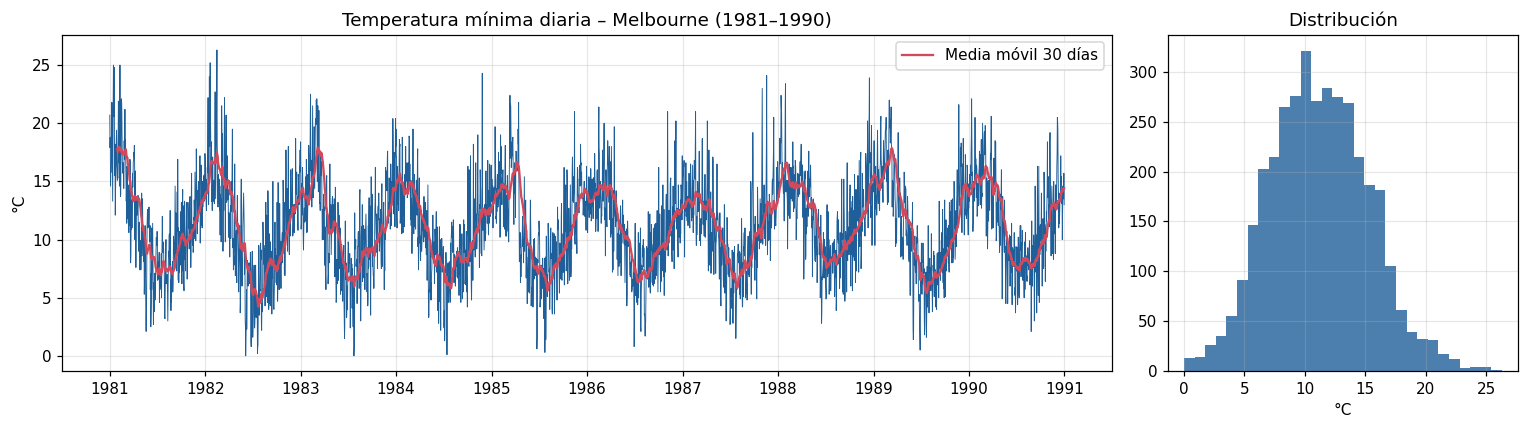

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
axes[0].plot(df.index, df["temp"], lw=0.6, color="#1f5f99")
axes[0].plot(df["temp"].rolling(30).mean(), color="#d1495b", lw=1.5, label="Media móvil 30 días")
axes[0].set_title("Temperatura mínima diaria – Melbourne (1981–1990)")
axes[0].set_ylabel("°C"); axes[0].legend()
axes[1].hist(df["temp"], bins=30, color="#1f5f99", alpha=0.8)
axes[1].set_title("Distribución"); axes[1].set_xlabel("°C")
plt.tight_layout(); plt.savefig("figuras/nb1_serie.png", bbox_inches="tight"); plt.show()

A simple vista se nota una estacionalidad anual muy marcada (veranos cerca de 15–20 °C y inviernos alrededor de 5–8 °C) y bastante ruido de un día a otro. No hay valores faltantes, así que no fue necesario imputar nada.

## 3. Preprocesamiento

Aquí tuve tres cuidados:

- **División temporal, no aleatoria.** En series de tiempo mezclar al azar hace que el modelo "vea el futuro". Por eso usé 1981–1987 para entrenamiento, 1988 para validación y 1989–1990 para prueba.
- **Escalado con estadísticas solo del entrenamiento.** El `StandardScaler` se ajusta con los datos de entrenamiento y luego se aplica al resto, para no filtrar información.
- **Ventanas deslizantes.** Cada muestra son 30 días consecutivos (entrada) y la temperatura del día 31 (objetivo).

In [4]:
VENTANA = 30

serie = df["temp"].values.astype("float32")
fechas = df.index

train_end = fechas <= "1987-12-31"
media, desv = serie[train_end].mean(), serie[train_end].std()
serie_esc = (serie - media) / desv

def crear_ventanas(x, ventana):
    X, y = [], []
    for i in range(len(x) - ventana):
        X.append(x[i:i + ventana])
        y.append(x[i + ventana])
    return np.array(X)[..., None], np.array(y)

X, y = crear_ventanas(serie_esc, VENTANA)
fechas_y = fechas[VENTANA:]          # fecha del valor que se quiere predecir

m_train = fechas_y <= "1987-12-31"
m_val = (fechas_y > "1987-12-31") & (fechas_y <= "1988-12-31")
m_test = fechas_y > "1988-12-31"

X_train, y_train = X[m_train], y[m_train]
X_val, y_val = X[m_val], y[m_val]
X_test, y_test = X[m_test], y[m_test]

print(f"Media / desviación (train): {media:.2f} °C / {desv:.2f} °C")
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

Media / desviación (train): 10.98 °C / 4.09 °C
X_train: (2525, 30, 1) | X_val: (365, 30, 1) | X_test: (730, 30, 1)


In [5]:
def desescalar(z):
    return np.asarray(z).ravel() * desv + media

def metricas(y_real, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_real, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))),
        "R2": float(r2_score(y_real, y_pred)),
    }

y_test_c = desescalar(y_test)

# Línea base ingenua (persistencia): "mañana va a hacer lo mismo que hoy"
pred_persistencia = desescalar(X_test[:, -1, 0])
res_base = metricas(y_test_c, pred_persistencia)
print("Persistencia →", {k: round(v, 3) for k, v in res_base.items()})

Persistencia → {'MAE': 1.953, 'RMSE': 2.481, 'R2': 0.635}


La línea base de persistencia es importante: si un modelo de deep learning no logra superar algo tan simple como "mañana igual que hoy", realmente no está aportando nada.

## 4. Modelos

### 4.1 LSTM sin atención (referencia)
La LSTM recorre los 30 días y solo usa su **último estado oculto** para predecir. Todo el contexto queda "comprimido" en un único vector, que es justamente la limitación que motivó la aparición de la atención.

In [6]:
def modelo_lstm(unidades=64):
    entrada = keras.Input(shape=(VENTANA, 1))
    h = layers.LSTM(unidades)(entrada)
    h = layers.Dense(32, activation="relu")(h)
    salida = layers.Dense(1)(h)
    return keras.Model(entrada, salida, name="LSTM_sin_atencion")

lstm = modelo_lstm()
lstm.summary()

Model: "LSTM_sin_atencion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

### 4.2 LSTM con atención aditiva (Bahdanau)

En vez de quedarme solo con el último estado, guardo los 30 estados ocultos $h_1, \dots, h_{30}$ y dejo que el modelo decida cuánto pesa cada uno. El procedimiento es:

1. **Puntaje** de cada paso frente al estado final $s$ (que hace de *query*):
$$e_t = v^\top \tanh(W_1 h_t + W_2 s)$$
2. **Pesos de atención** con softmax, para que sumen 1:
$$\alpha_t = \frac{\exp(e_t)}{\sum_{k} \exp(e_k)}$$
3. **Vector de contexto**, como un promedio ponderado de los estados:
$$c = \sum_t \alpha_t\, h_t$$

Al final concateno $c$ con $s$ y paso eso por una capa densa. Implementé la capa de atención a mano para que se vea claramente cada paso.

In [7]:
class AtencionBahdanau(layers.Layer):
    # Atención aditiva: compara cada estado del encoder con una consulta (query)

    def __init__(self, unidades, **kwargs):
        super().__init__(**kwargs)
        self.W1 = layers.Dense(unidades, use_bias=False)   # proyecta los estados h_t
        self.W2 = layers.Dense(unidades)                   # proyecta la consulta s
        self.v = layers.Dense(1, use_bias=False)           # reduce a un puntaje escalar

    def call(self, estados, consulta):
        # estados: (batch, T, H) | consulta: (batch, H)
        consulta = ops.expand_dims(consulta, 1)                              # (batch, 1, H)
        puntajes = self.v(ops.tanh(self.W1(estados) + self.W2(consulta)))   # (batch, T, 1)
        pesos = ops.softmax(puntajes, axis=1)                                # (batch, T, 1)
        contexto = ops.sum(pesos * estados, axis=1)                          # (batch, H)
        return contexto, ops.squeeze(pesos, -1)


def modelo_lstm_atencion(unidades=64):
    entrada = keras.Input(shape=(VENTANA, 1))
    estados, h_final, _ = layers.LSTM(unidades, return_sequences=True, return_state=True)(entrada)
    contexto, pesos = AtencionBahdanau(32, name="atencion")(estados, h_final)
    x = layers.Concatenate()([contexto, h_final])
    x = layers.Dense(32, activation="relu")(x)
    salida = layers.Dense(1)(x)
    modelo = keras.Model(entrada, salida, name="LSTM_con_atencion")
    modelo_pesos = keras.Model(entrada, pesos, name="pesos_atencion")   # para visualizar
    return modelo, modelo_pesos

lstm_att, modelo_pesos = modelo_lstm_atencion()
lstm_att.summary()

Model: "LSTM_con_atencion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 30, 64),  │     16,896 │ input_layer_1[0]… │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ atencion            │ [(None, 64),      │      4,160 │ lstm_1[0][0],     │
│ (AtencionBahdanau)  │ (None, 30)]       │            │ lstm_1[0][1]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ atencion[0][0],   │
│ (Concatenate)       │                   │            │ lstm_1[0][1]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │      4,128 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         33 │ dense_5[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 25,217 (98.50 KB)

 Trainable params: 25,217 (98.50 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Entrenamiento

Ambos modelos se entrenan con las mismas condiciones: optimizador Adam, pérdida MSE, lotes de 32 y *early stopping* sobre la pérdida de validación (paciencia de 8 épocas, restaurando los mejores pesos). Así la comparación es justa.

In [8]:
def entrenar(modelo, epocas=60):
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    hist = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=epocas, batch_size=32, callbacks=[parada], verbose=2)
    return hist

print("=== LSTM sin atención ===")
hist_lstm = entrenar(lstm)
print("\n=== LSTM con atención ===")
hist_att = entrenar(lstm_att)

=== LSTM sin atención ===
Epoch 1/60
79/79 - 5s - 66ms/step - loss: 0.4900 - mae: 0.5442 - val_loss: 0.3967 - val_mae: 0.4861
Epoch 2/60
79/79 - 1s - 14ms/step - loss: 0.4155 - mae: 0.5039 - val_loss: 0.3753 - val_mae: 0.4735
Epoch 3/60
79/79 - 1s - 16ms/step - loss: 0.3900 - mae: 0.4878 - val_loss: 0.3553 - val_mae: 0.4613
Epoch 4/60
79/79 - 1s - 14ms/step - loss: 0.3715 - mae: 0.4771 - val_loss: 0.3465 - val_mae: 0.4596
Epoch 5/60
79/79 - 1s - 14ms/step - loss: 0.3634 - mae: 0.4723 - val_loss: 0.3447 - val_mae: 0.4601
Epoch 6/60
79/79 - 1s - 14ms/step - loss: 0.3605 - mae: 0.4707 - val_loss: 0.3438 - val_mae: 0.4593
Epoch 7/60
79/79 - 1s - 14ms/step - loss: 0.3593 - mae: 0.4699 - val_loss: 0.3430 - val_mae: 0.4588
Epoch 8/60
79/79 - 2s - 20ms/step - loss: 0.3583 - mae: 0.4690 - val_loss: 0.3431 - val_mae: 0.4590
Epoch 9/60
79/79 - 2s - 22ms/step - loss: 0.3578 - mae: 0.4687 - val_loss: 0.3433 - val_mae: 0.4593
Epoch 10/60
79/79 - 1s - 14ms/step - loss: 0.3572 - mae: 0.4682 - val_loss

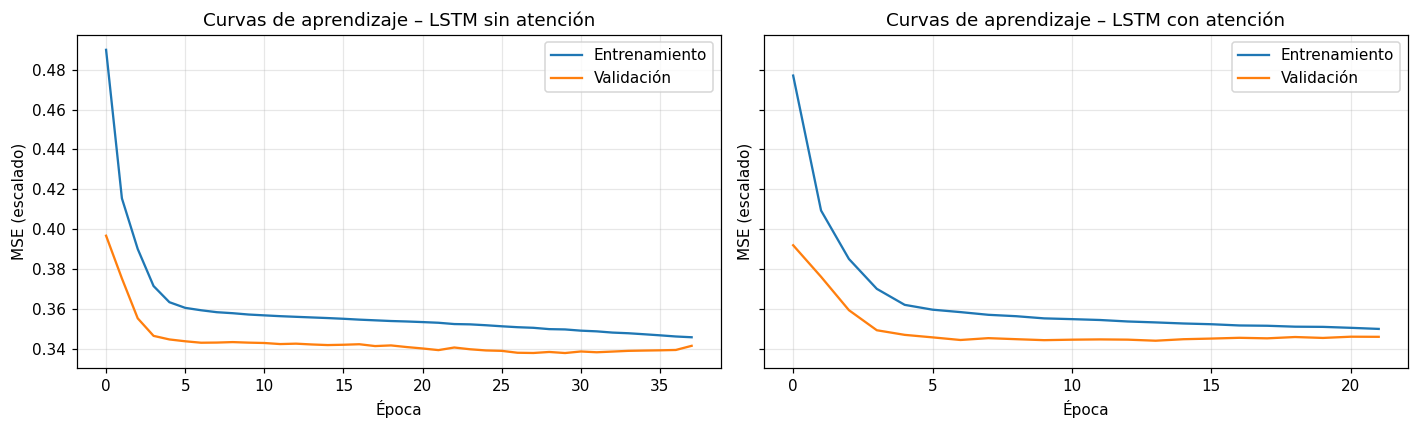

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, h, nombre in zip(axes, [hist_lstm, hist_att], ["LSTM sin atención", "LSTM con atención"]):
    ax.plot(h.history["loss"], label="Entrenamiento")
    ax.plot(h.history["val_loss"], label="Validación")
    ax.set_title(f"Curvas de aprendizaje – {nombre}")
    ax.set_xlabel("Época"); ax.set_ylabel("MSE (escalado)"); ax.legend()
plt.tight_layout(); plt.savefig("figuras/nb1_curvas.png", bbox_inches="tight"); plt.show()

## 6. Evaluación en el conjunto de prueba (1989–1990)

In [10]:
pred_lstm = desescalar(lstm.predict(X_test, verbose=0))
pred_att = desescalar(lstm_att.predict(X_test, verbose=0))

resultados = pd.DataFrame({
    "Persistencia (base)": res_base,
    "LSTM sin atención": metricas(y_test_c, pred_lstm),
    "LSTM con atención": metricas(y_test_c, pred_att),
}).T.round(3)
resultados["Épocas"] = ["-", len(hist_lstm.history["loss"]), len(hist_att.history["loss"])]
resultados

,MAE,RMSE,R2,Épocas
Persistencia (base),1.953,2.481,0.635,-
LSTM sin atención,1.712,2.176,0.719,38
LSTM con atención,1.712,2.175,0.719,22


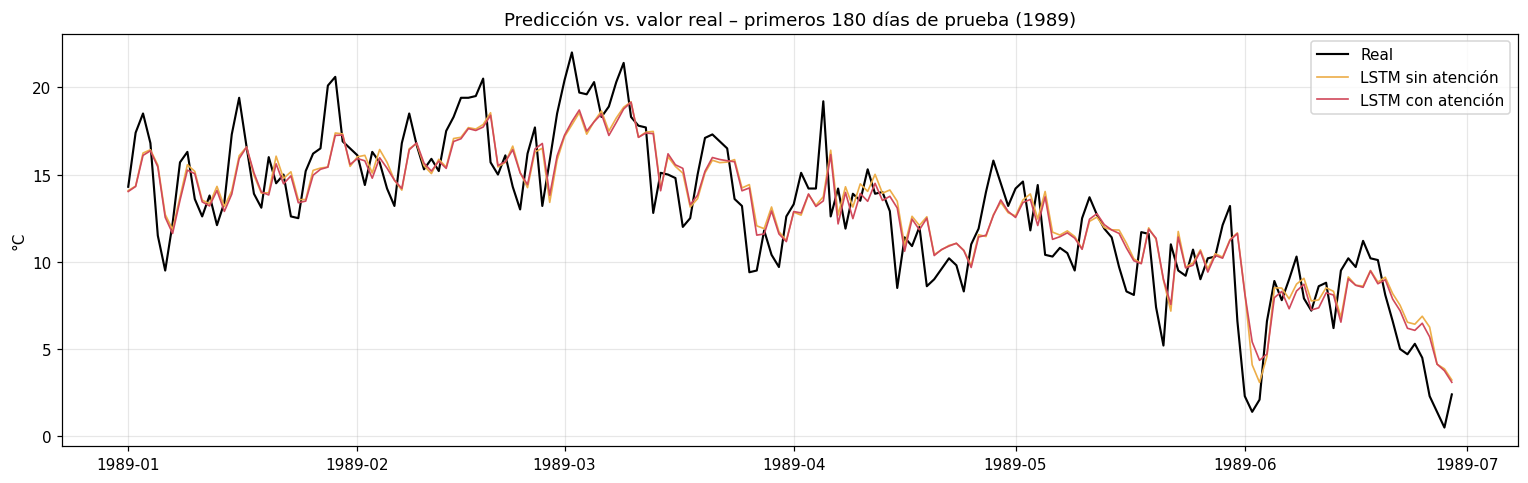

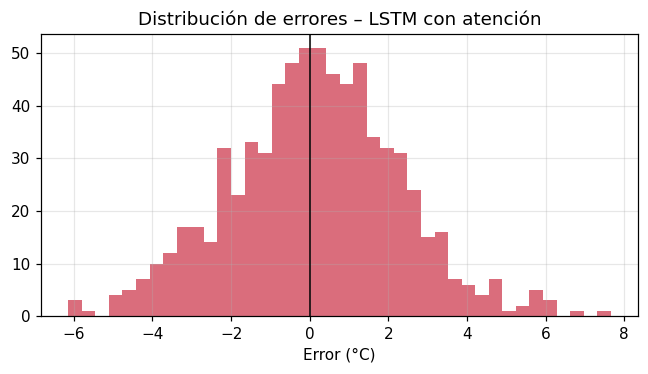

In [11]:
idx = slice(0, 180)
f_test = fechas_y[m_test]
plt.figure(figsize=(14, 4.5))
plt.plot(f_test[idx], y_test_c[idx], color="black", lw=1.4, label="Real")
plt.plot(f_test[idx], pred_lstm[idx], color="#edae49", lw=1.1, label="LSTM sin atención")
plt.plot(f_test[idx], pred_att[idx], color="#d1495b", lw=1.1, label="LSTM con atención")
plt.title("Predicción vs. valor real – primeros 180 días de prueba (1989)")
plt.ylabel("°C"); plt.legend()
plt.tight_layout(); plt.savefig("figuras/nb1_predicciones.png", bbox_inches="tight"); plt.show()

errores = y_test_c - pred_att
plt.figure(figsize=(6, 3.5))
plt.hist(errores, bins=40, color="#d1495b", alpha=0.8)
plt.axvline(0, color="black", lw=1)
plt.title("Distribución de errores – LSTM con atención"); plt.xlabel("Error (°C)")
plt.tight_layout(); plt.savefig("figuras/nb1_errores.png", bbox_inches="tight"); plt.show()

## 7. ¿En qué se fija el modelo? Análisis de los pesos de atención

Esta es para mí la parte más interesante, porque la atención no solo ayuda a predecir sino que también permite **interpretar** el modelo. Cada fila del mapa de calor es una muestra de prueba y cada columna es un día de la ventana (el día −1 es "ayer").

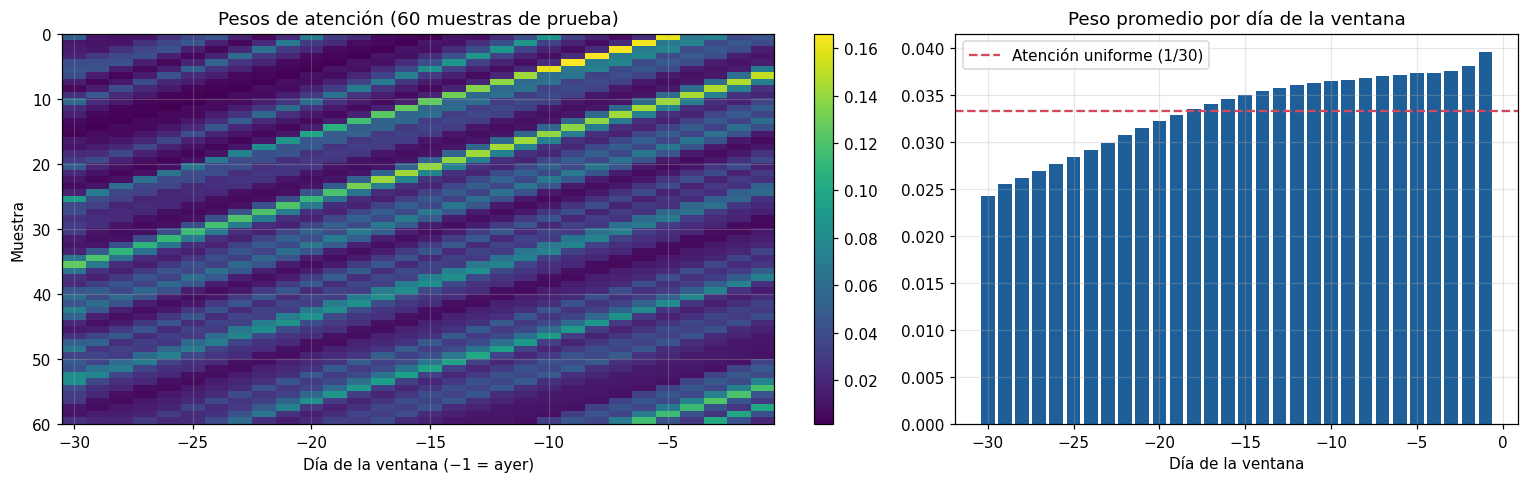

Días con mayor atención promedio: [-1, -2, -3, -4, -5]
Peso acumulado de los últimos 5 días: 19.0%


In [12]:
pesos_test = np.asarray(modelo_pesos.predict(X_test, verbose=0))   # (n, 30)
desfases = np.arange(-VENTANA, 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
im = axes[0].imshow(pesos_test[:60], aspect="auto", cmap="viridis",
                    extent=[-VENTANA - 0.5, -0.5, 60, 0])
axes[0].set_title("Pesos de atención (60 muestras de prueba)")
axes[0].set_xlabel("Día de la ventana (−1 = ayer)"); axes[0].set_ylabel("Muestra")
plt.colorbar(im, ax=axes[0], fraction=0.046)

axes[1].bar(desfases, pesos_test.mean(axis=0), color="#1f5f99")
axes[1].axhline(1 / VENTANA, color="#d1495b", ls="--", label="Atención uniforme (1/30)")
axes[1].set_title("Peso promedio por día de la ventana")
axes[1].set_xlabel("Día de la ventana"); axes[1].legend()
plt.tight_layout(); plt.savefig("figuras/nb1_atencion.png", bbox_inches="tight"); plt.show()

prom = pesos_test.mean(axis=0)
top = np.argsort(prom)[::-1][:5]
print("Días con mayor atención promedio:", [int(desfases[i]) for i in top])
print("Peso acumulado de los últimos 5 días: {:.1%}".format(prom[-5:].sum()))

En el mapa de calor aparecen unas **franjas diagonales** muy llamativas. Como cada muestra es la ventana del día siguiente corrida una posición, una diagonal significa que el modelo sigue mirando **el mismo día del calendario** mientras ese día va quedando más atrás en la ventana. Eso sugiere que la atención se está "enganchando" a días puntuales que tienen algo especial. Para comprobarlo, revisé si el día con más atención coincide con valores extremos de temperatura dentro de la ventana.

In [13]:
x_test_c = X_test[:, :, 0] * desv + media
dia_max_att = pesos_test.argmax(axis=1)
dia_min_temp = x_test_c.argmin(axis=1)
dia_max_temp = x_test_c.argmax(axis=1)

# Rango (posición ordenada) que ocupa el día más atendido dentro de su ventana: 0 = el más frío
rango = np.array([np.argsort(np.argsort(x_test_c[k]))[dia_max_att[k]] for k in range(len(x_test_c))])

corr = np.mean([np.corrcoef(pesos_test[k], x_test_c[k])[0, 1] for k in range(len(x_test_c))])
print(f"Correlación promedio entre peso de atención y temperatura del día: {corr:.3f}")
print(f"El día más atendido es el más frío de la ventana en el {np.mean(dia_max_att == dia_min_temp):.1%} de los casos")
print(f"El día más atendido es el más cálido de la ventana en el {np.mean(dia_max_att == dia_max_temp):.1%} de los casos")
print(f"El día más atendido está entre los 3 más fríos en el {np.mean(rango <= 2):.1%} de los casos")
print(f"El día más atendido está entre los 3 más cálidos en el {np.mean(rango >= VENTANA - 3):.1%} de los casos")

Correlación promedio entre peso de atención y temperatura del día: -0.876
El día más atendido es el más frío de la ventana en el 68.2% de los casos
El día más atendido es el más cálido de la ventana en el 0.0% de los casos
El día más atendido está entre los 3 más fríos en el 98.5% de los casos
El día más atendido está entre los 3 más cálidos en el 0.0% de los casos


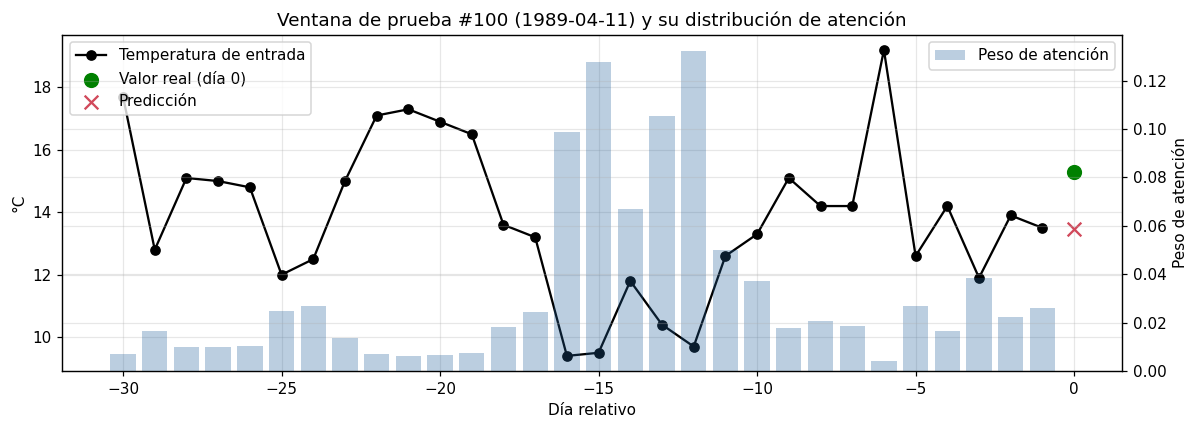

In [14]:
# Ejemplo puntual: una ventana de entrada junto con sus pesos de atención
i = 100
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(desfases, desescalar(X_test[i, :, 0]), marker="o", color="black", label="Temperatura de entrada")
ax1.scatter([0], [y_test_c[i]], color="green", s=80, zorder=3, label="Valor real (día 0)")
ax1.scatter([0], [pred_att[i]], color="#d1495b", marker="x", s=80, zorder=3, label="Predicción")
ax1.set_ylabel("°C"); ax1.set_xlabel("Día relativo")
ax2 = ax1.twinx()
ax2.bar(desfases, pesos_test[i], alpha=0.3, color="#1f5f99", label="Peso de atención")
ax2.set_ylabel("Peso de atención")
ax1.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.title(f"Ventana de prueba #{i} ({f_test[i].date()}) y su distribución de atención")
plt.tight_layout(); plt.savefig("figuras/nb1_ejemplo_atencion.png", bbox_inches="tight"); plt.show()

In [15]:
# Guardo las métricas para el informe y para compararlas con el Transformer del notebook 2
salida = {
    "metricas_test": resultados.drop(columns="Épocas").to_dict(orient="index"),
    "epocas": {"LSTM sin atención": len(hist_lstm.history["loss"]),
               "LSTM con atención": len(hist_att.history["loss"])},
    "parametros": {"LSTM sin atención": int(lstm.count_params()),
                   "LSTM con atención": int(lstm_att.count_params())},
    "atencion_promedio": prom.tolist(),
    "top_dias_atencion": [int(desfases[i]) for i in top],
    "corr_atencion_temp": float(corr),
    "pct_max_att_es_mas_frio": float(np.mean(dia_max_att == dia_min_temp)),
    "pct_max_att_es_mas_calido": float(np.mean(dia_max_att == dia_max_temp)),
    "pct_max_att_top3_frios": float(np.mean(rango <= 2)),
    "pct_max_att_top3_calidos": float(np.mean(rango >= VENTANA - 3)),
}
with open("resultados/nb1_metricas.json", "w", encoding="utf-8") as f:
    json.dump(salida, f, ensure_ascii=False, indent=2)
print(json.dumps(salida["metricas_test"], indent=2, ensure_ascii=False))

{
  "Persistencia (base)": {
    "MAE": 1.953,
    "RMSE": 2.481,
    "R2": 0.635
  },
  "LSTM sin atención": {
    "MAE": 1.712,
    "RMSE": 2.176,
    "R2": 0.719
  },
  "LSTM con atención": {
    "MAE": 1.712,
    "RMSE": 2.175,
    "R2": 0.719
  }
}


## 8. Conclusiones

- **Los dos modelos recurrentes le ganan con claridad a la línea base.** En prueba, la persistencia ("mañana igual que hoy") tuvo un MAE de 1,95 °C, y las dos LSTM bajaron a 1,71 °C, o sea cerca de un 12 % menos de error. El R² pasó de 0,64 a 0,72.
- **La atención no mejoró la precisión, pero sí cambió otras cosas.** La LSTM con atención y la LSTM sin atención quedaron prácticamente empatadas (MAE de 1,712 °C en ambos casos y RMSE de 2,175 frente a 2,176). Con solo 30 pasos, una LSTM alcanza a "recordar" toda la ventana sin problema, así que no hay mucho cuello de botella que resolver. La diferencia está en dos cosas: el modelo con atención convergió más rápido (el *early stopping* lo detuvo en la época 22, contra la 38 del modelo sin atención) y, sobre todo, ahora se puede **interpretar**.
- **El modelo aprendió a fijarse en los días más fríos.** Este fue el hallazgo que más me gustó. La correlación promedio entre el peso de atención y la temperatura de cada día es de −0,88. El día con más atención es el más frío de la ventana en el 68 % de los casos y está entre los 3 más fríos en el 98 %. Las franjas diagonales del mapa de calor muestran que, cuando aparece un día muy frío, el modelo lo sigue mirando mientras ese día va quedando atrás en las ventanas siguientes.
- **También hay un sesgo hacia lo reciente.** En promedio, los pesos crecen de forma suave del día −30 al día −1, y "ayer" es el día con más peso. Tiene sentido físico: la temperatura de mañana depende sobre todo de los últimos días.
- **Limitaciones.** Solo usé la temperatura como variable de entrada. Agregar información de calendario (día del año) u otras variables climáticas probablemente ayudaría más que complicar la arquitectura.